# 02 — Player-gameweek panel: sanity checks

Reviews `data/player_gw_panel.csv` built by `src/build_dataset.py`.

It covers last season (2025-26) and the current one, linked by each player's stable FPL `code`.

Each player is treated as an asset and each gameweek as a period; `total_points` is the period return.
Every trailing feature uses only earlier gameweeks, so this table can be backtested honestly.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

panel = pd.read_csv("../data/player_gw_panel.csv")
played = panel[panel["total_points"].notna()]
upcoming = panel[panel["total_points"].isna()]
print(panel.shape, "| played rows:", len(played), "| upcoming rows:", len(upcoming))
print(panel[panel["total_points"].notna()].groupby("season")["round"].agg(["min", "max", "count"]))

(34557, 39) | played rows: 33889 | upcoming rows: 668
         min  max  count
season                  
2025-26    1   38  29338
2026-27    1    7   4551


## 1. Spot-check one player

Compare these against the player's history on the FPL website. In row *n*, `pts_mean_3` should be the mean of the previous three rows' `total_points`, never including row *n* itself.

In [2]:
cols = ["round", "price_m", "difficulty", "minutes", "total_points",
        "pts_mean_3", "pts_mean_5", "pts_std_5", "play_rate_5", "xgi_per90_5"]
# The season hand-off: GW1's features come from the end of last season.
panel.loc[panel["web_name"] == "Haaland", ["season"] + cols].iloc[33:42]

,season,round,price_m,difficulty,minutes,total_points,pts_mean_3,pts_mean_5,pts_std_5,play_rate_5,xgi_per90_5
10920,2025-26,36,14.7,3.0,90.0,11.0,7.333333,5.2,4.868265,1.0,0.598333
10921,2025-26,37,14.7,4.0,90.0,9.0,10.333333,7.0,5.049752,1.0,0.795000
10922,2025-26,38,14.7,3.0,0.0,0.0,9.000000,8.4,4.219005,1.0,0.861667
10923,2026-27,1,15.5,3.0,90.0,2.0,6.666667,8.0,5.000000,0.8,0.918000
10924,2026-27,2,15.5,3.0,90.0,13.0,3.666667,5.8,4.658326,0.8,0.840000
10925,2026-27,3,15.5,2.0,90.0,9.0,5.000000,7.0,5.700877,0.8,0.870000
10926,2026-27,4,15.5,4.0,90.0,9.0,8.000000,6.6,5.412947,0.8,0.927500
10927,2026-27,5,15.6,3.0,90.0,6.0,10.333333,6.6,5.412947,0.8,0.960000
10928,2026-27,6,15.6,4.0,79.0,6.0,8.000000,7.8,4.086563,1.0,0.990000


## 2. Do the features carry any signal? (information coefficient)

The **information coefficient (IC)** is the rank correlation between a signal known before the deadline and the return that followed, calculated per gameweek.
In equity factor research an IC around 0.05–0.10 is already useful. We now have ~40 gameweeks of cross-sections, so the averages mean far more than they did with 7.

In [3]:
signals = ["pts_mean_3", "pts_mean_5", "pts_sharpe_5", "mins_mean_3",
           "start_rate_5", "xgi_per90_5", "price_m", "difficulty"]

def rank_ic(df, signal):
    d = df[[signal, "total_points"]].dropna()
    return d[signal].rank().corr(d["total_points"].rank()) if len(d) > 20 else float("nan")

ic = pd.DataFrame({
    s: played[played["gws_observed"] >= 3].groupby(["season", "round"]).apply(rank_ic, signal=s)
    for s in signals
})
ic.mean().round(3).to_frame("mean IC, all players")

,"mean IC, all players"
pts_mean_3,0.715
pts_mean_5,0.702
pts_sharpe_5,0.422
mins_mean_3,0.729
start_rate_5,0.673
xgi_per90_5,0.135
price_m,0.393
difficulty,-0.030


The **minutes / start-rate** signals rank highest: a player who doesn't play can't score.
That is why rotation risk sits at the base of the model. In the README this is the Layer 2 survival model.

These ICs are **inflated**, though. Hundreds of squad players almost never play, and anyone can predict their 0 points.
The more honest test asks which signals still separate players **among regular starters**. That is the decision you actually face when choosing between players who will play.

In [4]:
starters = played[(played["gws_observed"] >= 3) & (played["start_rate_5"] >= 0.8)]
ic_starters = pd.DataFrame({
    s: starters.groupby(["season", "round"]).apply(rank_ic, signal=s) for s in signals
})
summary = pd.DataFrame({
    "mean IC": ic_starters.mean(),
    "IC t-stat": ic_starters.mean() / ic_starters.std() * len(ic_starters) ** 0.5,
    "% GWs > 0": (ic_starters > 0).mean(),
})
summary.round(3).sort_values("mean IC", ascending=False)

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,mean IC,IC t-stat,% GWs > 0
mins_mean_3,0.190,15.500,1.000
pts_sharpe_5,0.170,10.747,0.952
pts_mean_3,0.158,12.587,1.000
pts_mean_5,0.150,9.819,0.929
price_m,0.139,10.041,0.952
start_rate_5,0.116,10.186,0.905
xgi_per90_5,0.084,6.543,0.881
difficulty,-0.150,-8.771,0.024


The **t-stat** reads the same way it does in factor research: the mean IC divided by its standard error across gameweeks. Above ~2 means the signal is consistently there, not just luck in a few weeks.

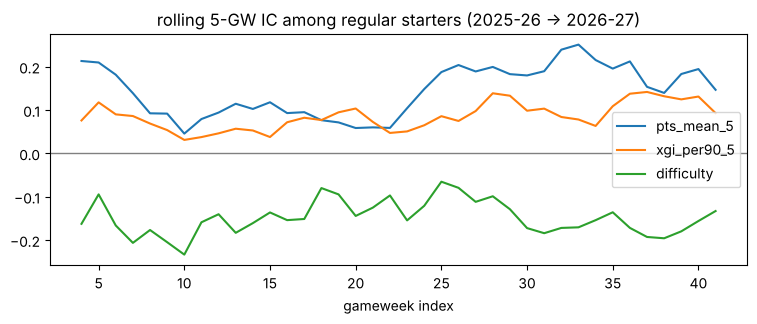

In [5]:
ax = ic_starters[["pts_mean_5", "xgi_per90_5", "difficulty"]].rolling(5).mean().reset_index(drop=True).plot(figsize=(9, 3))
ax.axhline(0, c="grey", lw=1)
ax.set_title("rolling 5-GW IC among regular starters (2025-26 → 2026-27)")
ax.set_xlabel("gameweek index")
plt.show()

## 3. Risk-return map for the next gameweek

Trailing mean points (expected return) against trailing volatility (risk), for regular starters. The dashed line is the 2-point appearance return, FPL's risk-free rate.
Players toward the upper-left give more return per unit of risk, the same reading as a Markowitz efficient frontier.

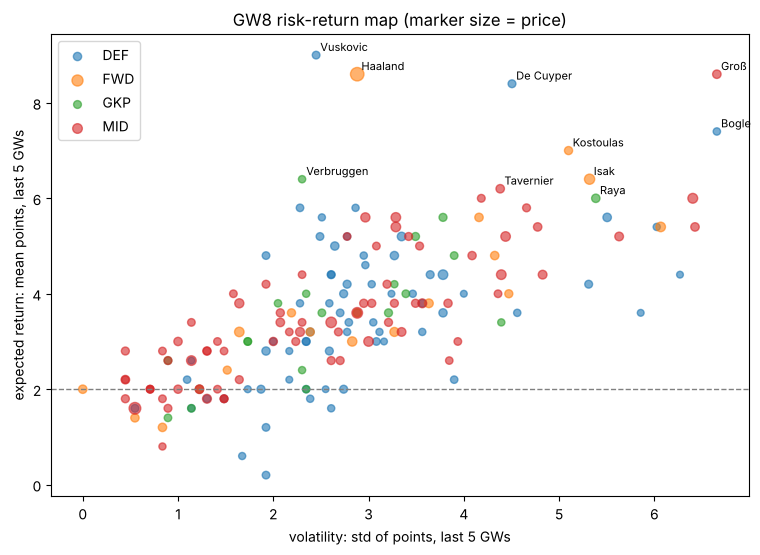

In [6]:
nxt = upcoming[(upcoming["gws_observed"] >= 5) & (upcoming["start_rate_5"] >= 0.8)]
fig, ax = plt.subplots(figsize=(9, 6))
for pos, grp in nxt.groupby("position"):
    ax.scatter(grp["pts_std_5"], grp["pts_mean_5"], label=pos, alpha=0.6, s=grp["price_m"] * 6)
for _, r in nxt.nlargest(10, "pts_mean_5").iterrows():
    ax.annotate(r["web_name"], (r["pts_std_5"], r["pts_mean_5"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(2, ls="--", c="grey", lw=1)
ax.set_xlabel("volatility: std of points, last 5 GWs")
ax.set_ylabel("expected return: mean points, last 5 GWs")
ax.set_title(f"GW{int(upcoming['round'].iloc[0])} risk-return map (marker size = price)")
ax.legend()
plt.show()

In [7]:
nxt.sort_values("pts_sharpe_5", ascending=False)[
    ["web_name", "position", "price_m", "pts_mean_5", "pts_std_5", "pts_sharpe_5", "pts_per_m_5", "difficulty"]
].head(15)

,web_name,position,price_m,pts_mean_5,pts_std_5,pts_sharpe_5,pts_per_m_5,difficulty
32455,Vuskovic,DEF,5.1,9.0,2.449490,2.857738,1.764706,4.0
10930,Haaland,FWD,15.7,8.6,2.880972,2.290893,0.547771,3.0
21838,Verbruggen,GKP,4.6,6.4,2.302173,1.911238,1.391304,4.0
20508,Bobb,MID,5.5,2.8,0.447214,1.788854,0.509091,2.0
19679,Van Hecke,DEF,4.9,5.8,2.280351,1.666410,1.183673,4.0
26175,Muharemović,DEF,5.0,4.8,1.923538,1.455651,0.960000,3.0
12103,F.Kadıoğlu,DEF,4.4,5.6,2.509980,1.434274,1.272727,4.0
19282,De Cuyper,DEF,5.3,8.4,4.505552,1.420470,1.584906,4.0
7757,Boscagli,DEF,4.5,5.8,2.863564,1.327018,1.288889,4.0
32045,Jacquet,DEF,5.1,5.2,2.489980,1.285151,1.019608,3.0


## 4. Rotation risk at a glance

Share of the last five gameweeks in which each player got any minutes. A few players are nailed starters, many never play, and the in-between group is where the minutes model earns its value.

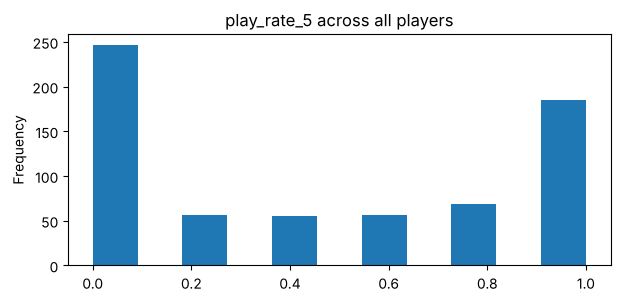

In [8]:
upcoming["play_rate_5"].plot.hist(bins=11, figsize=(7, 3), title="play_rate_5 across all players")
plt.show()

## Caveats

- Seasons before 2025-26 are left out on purpose. Defensive contribution points started that season, so older points were scored under different rules (a structural break).
- Five-game volatility is still a noisy risk estimate. A model can shrink it toward position averages.
- Trailing means are a **naive** expected-points estimate. The next step is a baseline model that has to beat them.
- Players who joined mid-season have short histories (`gws_observed`).